# LM15 Lab — Distributions in Finance

Companion notebook to **From Calculus to Kelly, LM15**. It rebuilds the module's exhibits and computational examples from TAIEX's total-return index, fits the Student-t from several starting points, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 0 | Data: TR23's returns, and the counting guard against an exact recount with `fractions.Fraction` |
| 1 | Binomial: up days in 292 blocks of 20 sessions (Exhibit 2, Example 1) |
| 2 | Poisson: Example 2, large moves by month (Example 3, Exhibit 3), the two limit regimes, months of unequal length |
| 3 | Normal: quantiles (Example 4) and the QQ plot (Exhibit 4, Example 5) |
| 4 | Lognormal: 23 calendar years (Example 6, Exhibit 5), `scipy.stats.lognorm` |
| 5 | Student-t: the gamma function (Example 7), two fits (Example 8), Exhibit 6 and Exhibit 7 |
| 6 | Tail measures: one day (Example 9), the limit regimes (Exhibit 8), chords (Example 10, Exhibit 9), tail means |
| 7 | Practice problems 2, 5, 7, 10, 11 and 12, and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv` (`date`, `price`): the closes of TAIEX's total-return index that FinMind's `TaiwanStockTotalReturnIndex` serves, 2 January 2003 – 8 October 2026. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** TR23: $T=5{,}849$ simple daily returns $R_t=P_t/P_{t-1}-1$ from 3 January 2003 to 8 October 2026. Moments divide by $T$ (or by the size of the part in use). A count of days with $R\le-x$ uses the guard `R <= -x + 1e-12`; an empirical quantile is LM14's order statistic $R_{(\lceil uT\rceil)}$, NumPy's `method="inverted_cdf"`. Every fitted distribution is in-sample, and the comparison of the 7% and 10% limit regimes is a stability check. Each `show` line prints a value beside the book's and stops if they differ.

In [1]:
from fractions import Fraction
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy import integrate, optimize, special, stats

DATA = Path("data")
EPS = 1e-12                                   # the counting guard
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value, and stop if they differ
    got = fmt(value) if callable(fmt) else format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def sig3(v):
    # three significant figures as the module prints expected days: whole numbers from 100, 1.5e-05 below 0.001
    if v >= 100:
        return f"{v:.0f}"
    return f"{v:#.3g}".rstrip(".") if v >= 1e-3 else f"{v:.1e}"

## Part 0 — Data and the counting guard

Index levels have two decimals, so a return such as $-3\%$ can be exact, and floating-point division then puts it on either side of the threshold (PITFALLS §5 of the repository). The guard `R <= -x + 1e-12` counts such ties; the cell checks it against an exact recount with `fractions.Fraction`.

In [2]:
tr = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"date": pl.Utf8, "price": pl.Float64}).sort("date")
tr = tr.with_columns((pl.col("price") / pl.col("price").shift(1) - 1).alias("R"))
ret = tr.slice(1)
R = ret["R"].to_numpy()
dates = ret["date"].to_list()
T = len(R)
show("T", T, ",", "5,849")
show("first return", dates[0], "s", "2003-01-03")
show("last return", dates[-1], "s", "2026-10-08")
Rbar, s = R.mean(), R.std()                   # divisor T
show("mean, %", 100 * Rbar, ".4f", "0.0625")
show("standard deviation, %", 100 * s, ".5f", "1.20836")

levels = [Fraction(str(p)) for p in tr["price"].to_list()]          # the two-decimal closes, exactly
RX = [levels[i] / levels[i - 1] - 1 for i in range(1, len(levels))]
rows = []
for k in range(1, 11):
    x = Fraction(k, 100)
    rows.append({"x": f"{k}%", "guarded": int((R <= -k / 100 + EPS).sum()), "exact": sum(1 for v in RX if v <= -x),
                 "unguarded": int((R <= -k / 100).sum())})
cnt = pl.DataFrame(rows)
print(cnt)
assert (cnt["guarded"] == cnt["exact"]).all()
big = np.abs(R) >= 0.03 - EPS
assert int(big.sum()) == sum(1 for v in RX if abs(v) >= Fraction(3, 100))
show("days with |R| >= 3%", int(big.sum()), "d", "175")

T: 5,849   [book: 5,849]
first return: 2003-01-03   [book: 2003-01-03]
last return: 2026-10-08   [book: 2026-10-08]
mean, %: 0.0625   [book: 0.0625]
standard deviation, %: 1.20836   [book: 1.20836]
shape: (10, 4)
┌─────┬─────────┬───────┬───────────┐
│ x   ┆ guarded ┆ exact ┆ unguarded │
│ --- ┆ ---     ┆ ---   ┆ ---       │
│ str ┆ i64     ┆ i64   ┆ i64       │
╞═════╪═════════╪═══════╪═══════════╡
│ 1%  ┆ 768     ┆ 768   ┆ 768       │
│ 2%  ┆ 252     ┆ 252   ┆ 252       │
│ 3%  ┆ 108     ┆ 108   ┆ 108       │
│ 4%  ┆ 44      ┆ 44    ┆ 44        │
│ 5%  ┆ 15      ┆ 15    ┆ 15        │
│ 6%  ┆ 6       ┆ 6     ┆ 6         │
│ 7%  ┆ 2       ┆ 2     ┆ 2         │
│ 8%  ┆ 2       ┆ 2     ┆ 2         │
│ 9%  ┆ 1       ┆ 1     ┆ 1         │
│ 10% ┆ 0       ┆ 0     ┆ 0         │
└─────┴─────────┴───────┴───────────┘
days with |R| >= 3%: 175   [book: 175]


## Part 1 — Up days in blocks of 20 sessions

Example 1 and Exhibit 2: the first 5,840 returns in 292 consecutive blocks; the last 9 returns are excluded.

blocks: 292   [book: 292]
left out: 9   [book: 9]
p hat = 3,200/5,840: 0.548   [book: 0.548]
blocks' mean: 10.96   [book: 10.96]
blocks' variance (divisor 292): 4.72   [book: 4.72]
binomial variance 20 x 0.548 x 0.452: 4.95   [book: 4.95]
Pr(X <= 5): 0.00677   [book: 0.00677]
blocks expected with <= 5 up days: 1.98   [book: 1.98]
Pr(X >= 16): 0.01807   [book: 0.01807]
blocks expected with >= 16 up days: 5.28   [book: 5.28]
observed: 2 and 3
shape: (14, 3)
┌─────────┬──────────┬───────────┐
│ up days ┆ observed ┆ binomial  │
│ ---     ┆ ---      ┆ ---       │
│ i64     ┆ i64      ┆ f64       │
╞═════════╪══════════╪═══════════╡
│ 4       ┆ 0        ┆ 0.387867  │
│ 5       ┆ 2        ┆ 1.504452  │
│ 6       ┆ 4        ┆ 4.558947  │
│ 7       ┆ 13       ┆ 11.051992 │
│ 8       ┆ 21       ┆ 21.769076 │
│ 9       ┆ 38       ┆ 35.182344 │
│ 10      ┆ 34       ┆ 46.909793 │
│ 11      ┆ 59       ┆ 51.691231 │
│ 12      ┆ 46       ┆ 46.992029 │
│ 13      ┆ 39       ┆ 35.052329 │
│ 14      ┆ 26 

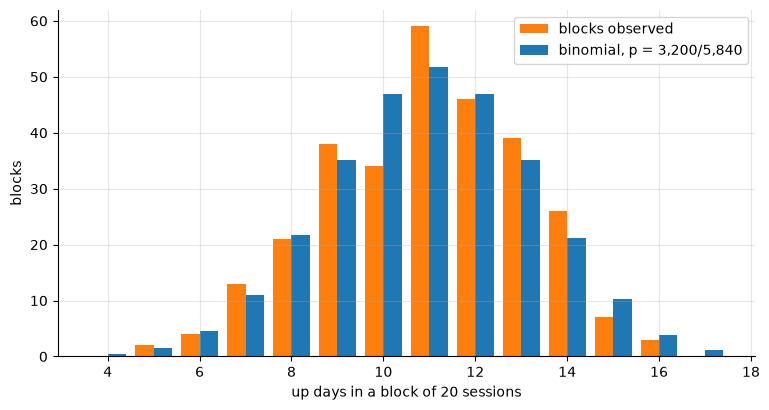

In [3]:
NB = T // 20
up = (R > 0).astype(int)
assert (R == 0).sum() == 0
blocks = up[: NB * 20].reshape(NB, 20).sum(axis=1)
p_hat = up[: NB * 20].mean()
show("blocks", NB, "d", "292")
show("left out", T - NB * 20, "d", "9")
show("p hat = 3,200/5,840", p_hat, ".3f", "0.548")
show("blocks' mean", blocks.mean(), ".2f", "10.96")
show("blocks' variance (divisor 292)", blocks.var(), ".2f", "4.72")
show("binomial variance 20 x 0.548 x 0.452", 20 * 0.548 * 0.452, ".2f", "4.95")
t5, t16 = stats.binom.cdf(5, 20, 0.548), stats.binom.sf(15, 20, 0.548)
show("Pr(X <= 5)", t5, ".3g", "0.00677")
show("blocks expected with <= 5 up days", 292 * t5, ".2f", "1.98")
show("Pr(X >= 16)", t16, ".4g", "0.01807")
show("blocks expected with >= 16 up days", 292 * t16, ".2f", "5.28")
print("observed:", int((blocks <= 5).sum()), "and", int((blocks >= 16).sum()))
j = np.arange(4, 18)
tab = pl.DataFrame({"up days": j, "observed": [int((blocks == v).sum()) for v in j],
                    "binomial": NB * stats.binom.pmf(j, 20, p_hat)})
print(tab)
show("expected outside 4..17", NB - tab["binomial"].sum(), ".2f", "0.34")
plt.bar(j - 0.2, tab["observed"], width=0.4, label="blocks observed", color="tab:orange")
plt.bar(j + 0.2, tab["binomial"], width=0.4, label="binomial, p = 3,200/5,840", color="tab:blue")
plt.xlabel("up days in a block of 20 sessions"); plt.ylabel("blocks"); plt.legend(); plt.show()

## Part 2 — Rare events: the Poisson

Example 2 compares a rare binomial with its Poisson limit; Example 3 and Exhibit 3 count the large moves ($\lvert R\rvert\ge3\%$) of each calendar month.

In [4]:
b20 = stats.binom.pmf([0, 1, 2], 20, 0.02992)
p20 = stats.poisson.pmf([0, 1, 2], 0.5984)
print(pl.DataFrame({"j": [0, 1, 2], "Bin(20, 0.02992)": b20, "Poisson(0.5984)": p20}))
show("largest gap", np.abs(b20 - p20).max(), ".4f", "0.0071")
for n, printed in ((20, "0.53711"), (250, "0.54186"), (10_000, "0.54226")):
    show(f"(1 - 0.612/n)^n, n = {n}", (1 - 0.612 / n) ** n, ".5f", printed)
show("e^-0.612", math.exp(-0.612), ".5f", "0.54227")
show("gap at n = 20", math.exp(-0.612) - (1 - 0.612 / 20) ** 20, ".4f", "0.0052")
show("e^-lambda lambda^2 / (2n) at n = 20", math.exp(-0.612) * 0.612**2 / 40, ".4f", "0.0051")

monthly = (ret.with_columns(pl.col("date").str.slice(0, 7).alias("month"),
                            (pl.col("R").abs() >= pl.lit(0.03 - EPS)).cast(pl.Int64).alias("big"))
              .group_by("month").agg(pl.col("big").sum(), pl.len().alias("sessions")).sort("month"))
counts = monthly["big"].to_numpy().astype(float)
show("months", monthly.height, "d", "286")
lam = counts.mean()
show("lambda hat = 175/286", lam, ".3f", "0.612")
show("variance (divisor 286)", counts.var(), ".3f", "1.846")
show("variance / mean", counts.var() / lam, ".2f", "3.02")
jj = np.arange(9)
print(pl.DataFrame({"large moves": jj, "observed": [int((counts == v).sum()) for v in jj],
                    "Poisson": 286 * stats.poisson.pmf(jj, lam)}))
show("Poisson: months with none", 286 * stats.poisson.pmf(0, lam), ".1f", "155.1")
show("Poisson: five or more", 286 * stats.poisson.sf(4, lam), ".3f", "0.123")
show("Poisson: eight or more", 286 * stats.poisson.sf(7, lam), ".1e", "8.1e-05")
print("months with eight:", monthly.filter(pl.col("big") == pl.lit(8))["month"].to_list())
pre = monthly["month"] < "2015-06"
for name, msk, printed in (("before June 2015", pre, "2.95"), ("from June 2015", ~pre, "3.01")):
    c = counts[msk.to_numpy()]
    show(f"variance / mean, {name}", c.var() / c.mean(), ".2f", printed)
nses = monthly["sessions"].to_numpy().astype(float)
p = 175 / 5849
show("variance with months of unequal length", nses.mean() * p * (1 - p) + p**2 * nses.var(), ".2f", "0.60")

shape: (3, 3)
┌─────┬──────────────────┬─────────────────┐
│ j   ┆ Bin(20, 0.02992) ┆ Poisson(0.5984) │
│ --- ┆ ---              ┆ ---             │
│ i64 ┆ f64              ┆ f64             │
╞═════╪══════════════════╪═════════════════╡
│ 0   ┆ 0.544692         ┆ 0.54969         │
│ 1   ┆ 0.335997         ┆ 0.328935        │
│ 2   ┆ 0.098449         ┆ 0.098417        │
└─────┴──────────────────┴─────────────────┘
largest gap: 0.0071   [book: 0.0071]
(1 - 0.612/n)^n, n = 20: 0.53711   [book: 0.53711]
(1 - 0.612/n)^n, n = 250: 0.54186   [book: 0.54186]
(1 - 0.612/n)^n, n = 10000: 0.54226   [book: 0.54226]
e^-0.612: 0.54227   [book: 0.54227]
gap at n = 20: 0.0052   [book: 0.0052]
e^-lambda lambda^2 / (2n) at n = 20: 0.0051   [book: 0.0051]
months: 286   [book: 286]
lambda hat = 175/286: 0.612   [book: 0.612]
variance (divisor 286): 1.846   [book: 1.846]
variance / mean: 3.02   [book: 3.02]
shape: (9, 3)
┌─────────────┬──────────┬────────────┐
│ large moves ┆ observed ┆ Poisson    │
│ --

## Part 3 — Normal quantiles and the QQ plot

Example 4 uses $\Phi^{-1}$ to four decimals with the printed $\bar R=0.0625\%$ and $s=1.2084\%$; the empirical quantiles are order statistics. Exhibit 4 thins its points for print; the lab plots all 5,849.

Phi^-1(0.95): 1.6449   [book: 1.6449]
normal 0.05 quantile, %: -1.925   [book: -1.925]
TAIEX 0.05 quantile (rank 293), %: -1.862   [book: -1.862]
Phi^-1(0.975): 1.9600   [book: 1.9600]
normal 0.025 quantile, %: -2.306   [book: -2.306]
TAIEX 0.025 quantile (rank 147), %: -2.648   [book: -2.648]
Phi^-1(0.99): 2.3263   [book: 2.3263]
normal 0.01 quantile, %: -2.749   [book: -2.749]
TAIEX 0.01 quantile (rank 59), %: -3.567   [book: -3.567]
Phi^-1(0.999): 3.0902   [book: 3.0902]
normal 0.001 quantile, %: -3.672   [book: -3.672]
TAIEX 0.001 quantile (rank 6), %: -6.313   [book: -6.313]
rank 6 is 2018-10-11
worst day (normal quantile): -3.758   [book: -3.758]
worst day (standardized): -8.079   [book: -8.079]
best day (standardized): 7.604   [book: 7.604]
rank 59: (-2.326,-3.004)   [book: (-2.326,-3.004)]


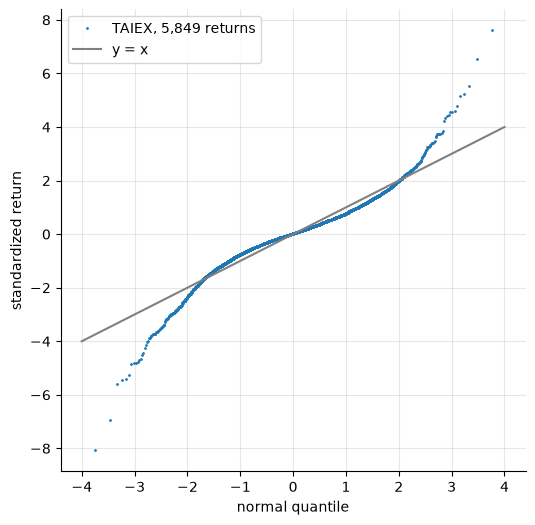

In [5]:
srt = np.sort(R)
rows = []
for u, ph, nq, eq in ((0.05, "1.6449", "-1.925", "-1.862"), (0.025, "1.9600", "-2.306", "-2.648"),
                      (0.01, "2.3263", "-2.749", "-3.567"), (0.001, "3.0902", "-3.672", "-6.313")):
    z = -stats.norm.ppf(u)
    show(f"Phi^-1({1 - u})", z, ".4f", ph)
    show(f"normal {u} quantile, %", 0.0625 - 1.2084 * float(ph), ".3f", nq)
    rank = math.ceil(Fraction(str(u)) * T)
    q = np.quantile(R, u, method="inverted_cdf")
    assert q == srt[rank - 1]
    show(f"TAIEX {u} quantile (rank {rank}), %", 100 * q, ".3f", eq)
print("rank 6 is", dates[int(np.argsort(R, kind="stable")[5])])
qq = stats.norm.ppf((np.arange(1, T + 1) - 0.5) / T)
zs = (srt - Rbar) / s
show("worst day (normal quantile)", qq[0], ".3f", "-3.758")
show("worst day (standardized)", zs[0], ".3f", "-8.079")
show("best day (standardized)", zs[-1], ".3f", "7.604")
show("rank 59", f"({qq[58]:.3f},{zs[58]:.3f})", "s", "(-2.326,-3.004)")
plt.figure(figsize=(6, 6))
plt.plot(qq, zs, ".", ms=2, label="TAIEX, 5,849 returns")
plt.plot([-4, 4], [-4, 4], color="grey", label="y = x")
plt.xlabel("normal quantile"); plt.ylabel("standardized return"); plt.legend(); plt.show()

## Part 4 — The lognormal for 23 calendar years

Example 6 and Exhibit 5: each year's growth factor is its last close over the previous year's last close; 2003 runs from the first close, 2 January 2003.

years: 23   [book: 23]
mu_X: 0.11646   [book: 0.11646]
sigma_X (divisor 23): 0.22207   [book: 0.22207]
median: 1.1235   [book: 1.1235]
mean: 1.1516   [book: 1.1516]
standard deviation: 0.2589   [book: 0.2589]
Pr(losing year), %: 30.0   [book: 30.0]
5% quantile: 0.7797   [book: 0.7797]
95% quantile: 1.6189   [book: 1.6189]
losing years: [2008, 2011, 2015, 2018, 2022]
empirical median: 1.1514   [book: 1.1514]
log returns in the window: 5,664   [book: 5,664]
m: 246   [book: 246]
model's annual mean: 0.1163   [book: 0.1163]
model's annual standard deviation: 0.1856   [book: 0.1856]
model's Pr(losing year), LM17's normal approximation, %: 26.5   [book: 26.5]


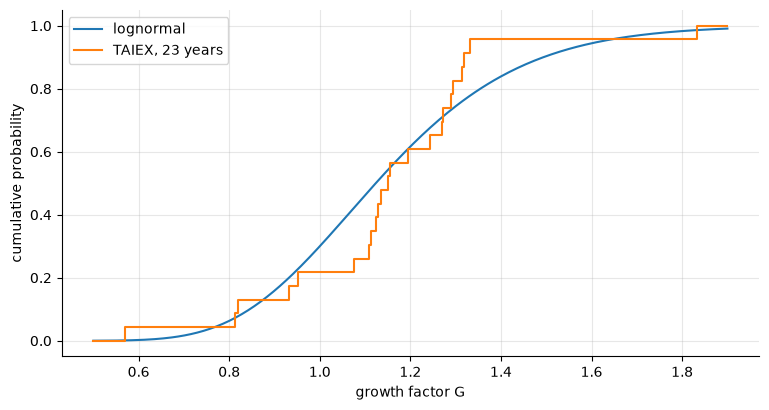

In [6]:
last = (tr.with_columns(pl.col("date").str.slice(0, 4).cast(pl.Int64).alias("year"))
          .group_by("year").agg(pl.col("price").last()).sort("year"))
first_close = tr["price"][0]
yr = last.filter(pl.col("year") <= pl.lit(2025))
prev = pl.concat([pl.Series("price", [first_close]), yr["price"].head(yr.height - 1)])
G = (yr["price"] / prev).to_numpy()
years = yr["year"].to_list()
show("years", len(G), "d", "23")
muX, sX = np.log(G).mean(), np.log(G).std()
show("mu_X", muX, ".5f", "0.11646")
show("sigma_X (divisor 23)", sX, ".5f", "0.22207")
lg = stats.lognorm(s=sX, scale=np.exp(muX))
show("median", lg.median(), ".4f", "1.1235")
show("mean", lg.mean(), ".4f", "1.1516")
show("standard deviation", lg.std(), ".4f", "0.2589")
show("Pr(losing year), %", 100 * lg.cdf(1), ".1f", "30.0")
show("5% quantile", lg.ppf(0.05), ".4f", "0.7797")
show("95% quantile", lg.ppf(0.95), ".4f", "1.6189")
print("losing years:", [y for y, g in zip(years, G) if g < 1])
show("empirical median", np.sort(G)[11], ".4f", "1.1514")
# LM17's model: 246 independent daily log returns, fitted to the same window
r = np.log1p(R)
w = r[np.array([d <= "2025-12-31" for d in dates])]
show("log returns in the window", len(w), ",", "5,664")
m = round(T / ((np.datetime64(tr["date"][-1]) - np.datetime64(tr["date"][0])).astype(int) / 365.25))
show("m", m, "d", "246")
show("model's annual mean", m * w.mean(), ".4f", "0.1163")
show("model's annual standard deviation", math.sqrt(m) * w.std(), ".4f", "0.1856")
show("model's Pr(losing year), LM17's normal approximation, %", 100 * stats.norm.cdf(-m * w.mean() / (math.sqrt(m) * w.std())), ".1f", "26.5")
g = np.linspace(0.5, 1.9, 300)
plt.plot(g, lg.cdf(g), label="lognormal")
plt.step(np.r_[0.5, np.sort(G), 1.9], np.r_[0, np.arange(1, 24) / 23, 1], where="post", label="TAIEX, 23 years")
plt.xlabel("growth factor G"); plt.ylabel("cumulative probability"); plt.legend(); plt.show()

## Part 5 — The Student-t

Example 7 checks the constant of (15.9); Example 8 fits the Student-t in two ways. `stats.t.fit` maximizes the likelihood numerically, so the cell repeats the fit with Nelder–Mead from four starting points: all must agree. Exhibit 6 and Exhibit 7 compare expected and observed days.

Gamma(0.5): 1.772454   [book: 1.772454]
Gamma(1.5): 0.886227   [book: 0.886227]
Gamma(2.5): 1.329340   [book: 1.329340]
constant at nu = 3: 0.3676   [book: 0.3676]
constant at nu = 1: 0.3183   [book: 0.3183]
constant at nu = 30: 0.3956   [book: 0.3956]
constant at nu = 1000: 0.3988   [book: 0.3988]
excess kurtosis: 5.27   [book: 5.27]
kurtosis fit: nu: 5.139   [book: 5.139]
kurtosis fit: scale, %: 0.944   [book: 0.944]
maximum likelihood: nu: 3.065   [book: 3.065]
maximum likelihood: location, %: 0.0997   [book: 0.0997]
maximum likelihood: scale, %: 0.7761   [book: 0.7761]
start nu =  3.0: nu 3.0653, location 0.0997%, scale 0.7761%, -log L -18091.016
start nu =  5.0: nu 3.0653, location 0.0997%, scale 0.7761%, -log L -18091.016
start nu =  2.2: nu 3.0653, location 0.0997%, scale 0.7761%, -log L -18091.016
start nu = 10.0: nu 3.0653, location 0.0997%, scale 0.7761%, -log L -18091.016
maximum likelihood: sigma, %: 1.317   [book: 1.317]
shape: (9, 6)
┌─────┬────────┬─────────┬────────────

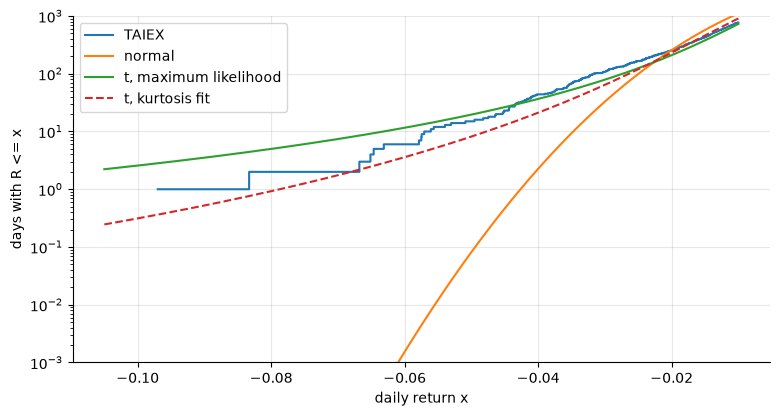

In [7]:
for a, printed in ((0.5, "1.772454"), (1.5, "0.886227"), (2.5, "1.329340")):
    show(f"Gamma({a})", special.gamma(a), ".6f", printed)
const = lambda nu: math.exp(special.gammaln((nu + 1) / 2) - special.gammaln(nu / 2)) / math.sqrt(nu * math.pi)
for nu, printed in ((3, "0.3676"), (1, "0.3183"), (30, "0.3956"), (1000, "0.3988")):
    show(f"constant at nu = {nu}", const(nu), ".4f", printed)

exk = stats.kurtosis(R)                       # excess kurtosis, divisor-T moments
show("excess kurtosis", exk, ".2f", "5.27")
nu_k = 4 + 6 / exk
sc_k = s * math.sqrt((nu_k - 2) / nu_k)
show("kurtosis fit: nu", nu_k, ".3f", "5.139")
show("kurtosis fit: scale, %", 100 * sc_k, ".3f", "0.944")
nu_m, loc_m, sc_m = stats.t.fit(R)
show("maximum likelihood: nu", nu_m, ".3f", "3.065")
show("maximum likelihood: location, %", 100 * loc_m, ".4f", "0.0997")
show("maximum likelihood: scale, %", 100 * sc_m, ".4f", "0.7761")
nll = lambda p: -stats.t.logpdf(R, p[0], p[1], math.exp(p[2])).sum() if p[0] > 0.5 else 1e18
for start in ((3.0, Rbar, math.log(0.6 * s)), (5.0, 0.0, math.log(s)), (2.2, 0.001, math.log(0.007)),
              (10.0, Rbar, math.log(0.8 * s))):
    res = optimize.minimize(nll, np.array(start), method="Nelder-Mead",
                            options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 20000, "maxfev": 40000})
    print(f"start nu = {start[0]:>4}: nu {res.x[0]:.4f}, location {100 * res.x[1]:.4f}%, "
          f"scale {100 * math.exp(res.x[2]):.4f}%, -log L {res.fun:.3f}")
    assert abs(res.x[0] - nu_m) < 1e-3
show("maximum likelihood: sigma, %", 100 * sc_m * math.sqrt(nu_m / (nu_m - 2)), ".3f", "1.317")

xs = [k / 100 for k in range(2, 11)]
tab = pl.DataFrame({
    "x": [f"{k}%" for k in range(2, 11)],
    "z": [round((-x - Rbar) / s, 3) for x in xs],
    "normal": [sig3(T * stats.norm.cdf((-x - Rbar) / s)) for x in xs],
    "t, kurtosis fit": [sig3(T * stats.t.cdf((-x - Rbar) / sc_k, nu_k)) for x in xs],
    "t, maximum likelihood": [sig3(T * stats.t.cdf(-x, nu_m, loc_m, sc_m)) for x in xs],
    "TAIEX": [int((R <= -x + EPS).sum()) for x in xs]})
print(tab)
assert tab["t, maximum likelihood"].to_list() == ["210", "79.0", "36.6", "19.6", "11.6", "7.41", "5.00", "3.52", "2.57"]
assert tab["TAIEX"].to_list() == [252, 108, 44, 15, 6, 2, 2, 1, 0]
grid = np.linspace(-0.105, -0.01, 400)
plt.semilogy(srt[srt <= -0.01 + EPS], np.arange(1, int((R <= -0.01 + EPS).sum()) + 1), drawstyle="steps-post", label="TAIEX")
plt.semilogy(grid, T * stats.norm.cdf((grid - Rbar) / s), label="normal")
plt.semilogy(grid, T * stats.t.cdf(grid, nu_m, loc_m, sc_m), label="t, maximum likelihood")
plt.semilogy(grid, T * stats.t.cdf((grid - Rbar) / sc_k, nu_k), "--", label="t, kurtosis fit")
plt.ylim(1e-3, 1e3); plt.xlabel("daily return x"); plt.ylabel("days with R <= x"); plt.legend(); plt.show()

## Part 6 — Tail measures

Example 9: one day against four tail measures. Exhibit 8: the two limit regimes, each fitted on its own (a stability check). Example 10 and Exhibit 9: chords (15.13) of the guarded counts.

excess kurtosis to 2 April 2025: 4.25   [book: 4.25]
excess kurtosis to 7 April 2025: 4.94   [book: 4.94]
1% quantile before, %: -3.538   [book: -3.538]
1% quantile after, %: -3.543   [book: -3.543]
chord -5% to -6% before (12 and 4 days): 6.03   [book: 6.03]
chord -5% to -6% after (13 and 5 days): 5.24   [book: 5.24]
without 7 April 2025: 4.71   [book: 4.71]
four largest moves: ['2025-04-07', '2025-04-10', '2024-08-05', '2026-07-31']
without the four largest: 3.74   [book: 3.74]
top ten: share of the fourth powers, %: 35.0   [book: 35.0]
shape: (3, 8)
┌───────────┬──────┬───────┬──────────┬──────────┬──────────┬───────────────┬──────────────────────┐
│ part      ┆ T    ┆ s %   ┆ excess   ┆ nu by    ┆ nu by ML ┆ 1% quantile % ┆ R <= -3% per 1,000   │
│ ---       ┆ ---  ┆ ---   ┆ kurtosis ┆ kurtosis ┆ ---      ┆ ---           ┆ ---                  │
│ str       ┆ i64  ┆ f64   ┆ ---      ┆ ---      ┆ f64      ┆ f64           ┆ f64                  │
│           ┆      ┆       ┆ f64     

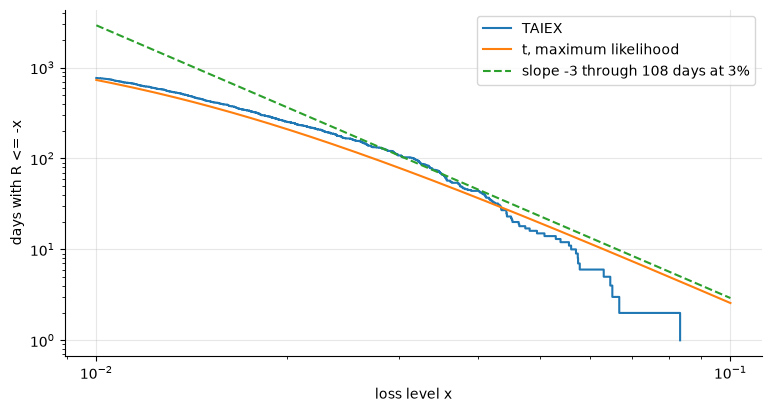

In [8]:
i7 = dates.index("2025-04-07")
eve, aft = R[:i7], R[: i7 + 1]
show("excess kurtosis to 2 April 2025", stats.kurtosis(eve), ".2f", "4.25")
show("excess kurtosis to 7 April 2025", stats.kurtosis(aft), ".2f", "4.94")
show("1% quantile before, %", 100 * np.quantile(eve, 0.01, method="inverted_cdf"), ".3f", "-3.538")
show("1% quantile after, %", 100 * np.quantile(aft, 0.01, method="inverted_cdf"), ".3f", "-3.543")
for name, part, printed in (("before", eve, "6.03"), ("after", aft, "5.24")):
    n5, n6 = int((part <= -0.05 + EPS).sum()), int((part <= -0.06 + EPS).sum())
    show(f"chord -5% to -6% {name} ({n5} and {n6} days)", math.log(n5 / n6) / math.log(1.2), ".2f", printed)
show("without 7 April 2025", stats.kurtosis(np.delete(R, i7)), ".2f", "4.71")
dev = R - Rbar
top4 = np.argsort(-np.abs(dev), kind="stable")[:4]
print("four largest moves:", [dates[i] for i in top4])
show("without the four largest", stats.kurtosis(np.delete(R, top4)), ".2f", "3.74")
top10 = np.argsort(-dev**4, kind="stable")[:10]
show("top ten: share of the fourth powers, %", 100 * (dev[top10] ** 4).sum() / (dev**4).sum(), ".1f", "35.0")

reg = ret.with_columns((pl.col("date") < pl.lit("2015-06-01")).alias("limit7"))
rows = []
for name, part in (("full", ret), ("7% limit", reg.filter(pl.col("limit7"))), ("10% limit", reg.filter(~pl.col("limit7")))):
    x = part["R"].to_numpy()
    ek = stats.kurtosis(x)
    rows.append({"part": name, "T": len(x), "s %": round(100 * x.std(), 3), "excess kurtosis": round(ek, 2),
                 "nu by kurtosis": round(4 + 6 / ek, 2), "nu by ML": round(stats.t.fit(x)[0], 3),
                 "1% quantile %": round(100 * np.quantile(x, 0.01, method="inverted_cdf"), 3),
                 "R <= -3% per 1,000": round(1000 * (x <= -0.03 + EPS).sum() / len(x), 1)})
x9 = pl.DataFrame(rows)
print(x9)
assert x9["nu by ML"].to_list() == [3.065, 2.99, 3.237] and x9["excess kurtosis"].to_list() == [5.27, 3.39, 8.07]

n = {k: int((R <= -k / 100 + EPS).sum()) for k in range(2, 7)}
chord = lambda n1, n2, x1, x2: math.log(n1 / n2) / math.log(x2 / x1)
for k, printed in zip(range(2, 6), ("2.09", "3.12", "4.82", "5.03")):
    show(f"chord {k}% to {k + 1}%", chord(n[k], n[k + 1], k, k + 1), ".2f", printed)
show("chord 3% to 6%", chord(n[3], n[6], 3, 6), ".2f", "4.17")
tail = R[R <= -0.05 + EPS]
show("mean of the days at or below -5%, %", 100 * tail.mean(), ".2f", "-6.26")
z5 = (-0.05 - Rbar) / s
show("normal (5.11), %", 100 * (Rbar - s * stats.norm.pdf(z5) / stats.norm.cdf(z5)), ".2f", "-5.26")
num = integrate.quad(lambda v: v * stats.t.pdf(v, nu_m, loc_m, sc_m), -np.inf, -0.05)[0]
show("maximum-likelihood t, %", 100 * num / stats.t.cdf(-0.05, nu_m, loc_m, sc_m), ".2f", "-7.57")
lev = np.linspace(0.01, 0.10, 300)
loss = np.sort(-R[R <= -0.01 + EPS])
plt.loglog(np.r_[0.01, loss[:-1]], len(loss) - np.arange(len(loss)), drawstyle="steps-post", label="TAIEX")
plt.loglog(lev, T * stats.t.cdf(-lev, nu_m, loc_m, sc_m), label="t, maximum likelihood")
plt.loglog(lev, n[3] * (lev / 0.03) ** -3.0, "--", label="slope -3 through 108 days at 3%")
plt.xlabel("loss level x"); plt.ylabel("days with R <= -x"); plt.legend(); plt.show()

## Part 7 — Practice problems 2, 5, 7, 10, 11 and 12

In [9]:
# Problem 2
show("P2 Pr(X = 0)", stats.poisson.pmf(0, 0.612), ".3g", "0.542")
show("P2 Pr(X >= 5)", stats.poisson.sf(4, 0.612), ".3g", "0.000431")
show("P2 months without a large move", 286 * stats.poisson.pmf(0, 0.612), ".1f", "155.1")
show("P2 months with five or more, 286 x 0.000431", 286 * 0.000431, ".3f", "0.123")
# Problem 5
show("P5 normal 1%, %", 0.0625 - 1.2084 * 2.3263, ".3f", "-2.749")
show("P5 normal 99%, %", 0.0625 + 1.2084 * 2.3263, ".3f", "2.874")
show("P5 TAIEX 99% (rank 5,791), %", 100 * srt[5790], ".3f", "3.125")
# Problem 7
lg7 = stats.lognorm(s=0.22207, scale=np.exp(0.11646))
for name, v, printed in (("median", lg7.median(), "1.1235"), ("mean", lg7.mean(), "1.1516"), ("sd", lg7.std(), "0.2589"),
                         ("5%", lg7.ppf(0.05), "0.7797"), ("95%", lg7.ppf(0.95), "1.6189")):
    show(f"P7 {name}", v, ".4f", printed)
# Problem 10
for (a, b), printed in (((2, 4), "2.52"), ((4, 6), "4.91"), ((2, 6), "3.40")):
    show(f"P10 chord {a}% to {b}%", chord(n[a], n[b], a, b), ".2f", printed)
ml_days = {2: 210, 4: 36.6, 6: 11.6}              # the maximum-likelihood fit's days, as the module prints them
for (a, b), printed in (((2, 4), "2.52"), ((4, 6), "2.83"), ((2, 6), "2.64")):
    show(f"P10 maximum-likelihood chord {a}% to {b}%", chord(ml_days[a], ml_days[b], a, b), ".2f", printed)
# Problem 11: see the table of Part 6
show("P11 rank of the 1% quantile before June 2015", math.ceil(0.01 * 3077), "d", "31")
show("P11 rank after", math.ceil(0.01 * 2772), "d", "28")
# Problem 12
show("P12 days >= +3%", int((R >= 0.03 - EPS).sum()), "d", "67")
show("P12 days >= +5%", int((R >= 0.05 - EPS).sum()), "d", "13")
show("P12 normal at +3%", T * stats.norm.sf((0.03 - Rbar) / s), ".1f", "44.0")
show("P12 normal at +5%", T * stats.norm.sf((0.05 - Rbar) / s), ".3f", "0.128")
show("P12 t at +3%", T * stats.t.sf(0.03, nu_m, loc_m, sc_m), ".1f", "94.2")
show("P12 t at +5%", T * stats.t.sf(0.05, nu_m, loc_m, sc_m), ".1f", "22.0")

P2 Pr(X = 0): 0.542   [book: 0.542]
P2 Pr(X >= 5): 0.000431   [book: 0.000431]
P2 months without a large move: 155.1   [book: 155.1]
P2 months with five or more, 286 x 0.000431: 0.123   [book: 0.123]
P5 normal 1%, %: -2.749   [book: -2.749]
P5 normal 99%, %: 2.874   [book: 2.874]
P5 TAIEX 99% (rank 5,791), %: 3.125   [book: 3.125]
P7 median: 1.1235   [book: 1.1235]
P7 mean: 1.1516   [book: 1.1516]
P7 sd: 0.2589   [book: 0.2589]
P7 5%: 0.7797   [book: 0.7797]
P7 95%: 1.6189   [book: 1.6189]
P10 chord 2% to 4%: 2.52   [book: 2.52]
P10 chord 4% to 6%: 4.91   [book: 4.91]
P10 chord 2% to 6%: 3.40   [book: 3.40]
P10 maximum-likelihood chord 2% to 4%: 2.52   [book: 2.52]
P10 maximum-likelihood chord 4% to 6%: 2.83   [book: 2.83]
P10 maximum-likelihood chord 2% to 6%: 2.64   [book: 2.64]
P11 rank of the 1% quantile before June 2015: 31   [book: 31]
P11 rank after: 28   [book: 28]
P12 days >= +3%: 67   [book: 67]
P12 days >= +5%: 13   [book: 13]
P12 normal at +3%: 44.0   [book: 44.0]
P12 norma

### Extension: a Student-t for five-session log returns

Sum the daily log returns $r_t=\ln(1+R_t)$ over non-overlapping blocks of five sessions, and fit a Student-t to these five-session log returns by maximum likelihood. Compare its $\nu$ and the 1% quantile of the five-session log returns with those of the daily log returns (the module's 3.065 and −3.567% are for simple returns). Treat the comparison as a stability check and draw no conclusion yet: LM17 studies sums of log returns, their kurtosis included, and LM19 the sampling error of such statistics.

In [10]:
r = np.log1p(R)                               # daily log returns
n5 = T // 5
r5 = r[: n5 * 5].reshape(n5, 5).sum(axis=1)   # non-overlapping five-session log returns
nu5, loc5, sc5 = stats.t.fit(r5)
nu1 = stats.t.fit(r)[0]                       # daily log returns, like with like
print(f"{T} daily log returns: Student-t nu {nu1:.3f}; "
      f"1% quantile {100 * np.quantile(r, 0.01, method='inverted_cdf'):.3f}% (log return)")
print(f"{n5} five-session log returns: Student-t nu {nu5:.3f}; "
      f"1% quantile {100 * np.quantile(r5, 0.01, method='inverted_cdf'):.3f}% (log return)")
# your code: other block lengths (10, 20); LM17 computes the kurtosis of such sums

5849 daily log returns: Student-t nu 3.044; 1% quantile -3.632% (log return)
1169 five-session log returns: Student-t nu 3.870; 1% quantile -8.667% (log return)
